# <a id='toc1_'></a>[Modelado](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [Modelado](#toc1_)    
  - [Configuración](#toc1_1_)    
  - [Datos](#toc1_2_)    
  - [Función de entrenamiento](#toc1_3_)    
  - [Experimento 1: extracción de características](#toc1_4_)    
  - [Experimento 2: fine-tuning](#toc1_5_)    
  - [Experimento 3: fine-tuning con pesos de clase](#toc1_6_)    
  - [Comparación de experimentos](#toc1_7_)    
  - [Evaluación en test](#toc1_8_)    
  - [Experimentos con más épocas](#toc1_9_)    
    - [Experimento 4: extracción de características (30 épocas)](#toc1_9_1_)    
    - [Experimento 5: fine-tuning (30 épocas)](#toc1_9_2_)    
    - [Experimento 6: fine-tuning con pesos de clase (30 épocas)](#toc1_9_3_)    
    - [Comparación de los seis experimentos](#toc1_9_4_)    
    - [¿Cuándo habría parado el early stopping?](#toc1_9_5_)    
  - [Modelos multitarea](#toc1_10_)    
    - [Etiquetas](#toc1_10_1_)    
    - [Experimento 7](#toc1_10_2_)    
    - [Resultados](#toc1_10_3_)    
    - [Modelo multitarea: color y género](#toc1_10_4_)    
      - [Etiquetas](#toc1_10_4_1_)    
      - [Experimento 8](#toc1_10_4_2_)    
      - [Resultados](#toc1_10_4_3_)    
    - [Modelo multitarea: género sin color](#toc1_10_5_)    
      - [Etiquetas](#toc1_10_5_1_)    
      - [Experimento 9](#toc1_10_5_2_)    
      - [Resultados](#toc1_10_5_3_)    
  - [Resumen](#toc1_11_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

> En este notebook entrenamos el modelo baseline para clasificar la imagen de un producto en su `masterCategory`. Usamos transfer learning con una ResNet18 preentrenada en ImageNet y registramos cada experimento en MLflow. Partimos del dataset con el split de `03_preprocessing` (`styles_splits.csv`).

**Objetivos:**
1. Preparar los `DataLoader` de train, val y test.
2. Experimento 1: extracción de características (solo entrenamos la última capa).
3. Experimento 2: fine-tuning de toda la red.
4. Experimento 3: fine-tuning con pesos de clase.
5. Comparar los experimentos en validación y evaluar el mejor en test.
6. Experimentos 4-6: repetir los tres anteriores con más épocas y analizar el early stopping.
7. Modelo multitarea: una sola red que predice `masterCategory`, `subCategory` y `articleType` a la vez.
8. Modelo multitarea v2: añadir el color (`baseColour`) y el género (`gender`).
9. Modelo multitarea v3 (experimento de control): género sin color, para ver qué provoca la pérdida del v2.

In [ ]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import mlflow
from collections import Counter
from torch import nn
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Estilo de gráficos
plt.style.use('seaborn-v0_8-whitegrid')

from fashion_mlops.config import PROCESSED_DATA_DIR, IMAGES_DIR, IMAGE_SIZE, RANDOM_STATE
from fashion_mlops.data.dataset import make_loaders
from fashion_mlops.models.train import get_device, build_model, fit, predict, compute_metrics
from fashion_mlops.models.tracking import setup_mlflow
from fashion_mlops.utils.visualizations import show_images
from fashion_mlops.data.make_dataset import build_multitask_labels
from fashion_mlops.models.multitask import MultiTaskResNet, fit_multitask, predict_multitask

## <a id='toc1_1_'></a>[Configuración](#toc0_)

In [ ]:
BATCH_SIZE = 64
NUM_WORKERS = 4
EPOCHS_FROZEN = 3
EPOCHS_FINE_TUNING = 5

torch.manual_seed(RANDOM_STATE)
device = get_device()

# Base de datos local de MLflow (mlflow.db) y experimento "masterCategory"
setup_mlflow()

print(f"Dispositivo: {device}")

Dispositivo: mps


## <a id='toc1_2_'></a>[Datos](#toc0_)

In [3]:
df = pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv")

with open(PROCESSED_DATA_DIR / "label_mappings.json") as f:
    label_mappings = json.load(f)

with open(PROCESSED_DATA_DIR / "class_weights.json") as f:
    class_weights = json.load(f)["masterCategory"]

classes = list(label_mappings["masterCategory"])

loaders = make_loaders(df, IMAGES_DIR, label_col="masterCategory_idx", batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

for split, loader in loaders.items():
    print(f"{split}: {len(loader.dataset)} imágenes")

train: 31723 imágenes
val: 6346 imágenes
test: 6345 imágenes


## <a id='toc1_3_'></a>[Función de entrenamiento](#toc0_)

Para no repetir código en cada experimento, definimos una función que entrena el modelo y registra en MLflow los parámetros, las métricas de validación por época (lo hace `fit`), las mejores métricas y el modelo final:

In [4]:
results = {}

# Ejemplo de entrada para que MLflow registre la firma del modelo (forma de la entrada y la salida)
input_example = np.zeros((1, 3, *IMAGE_SIZE), dtype=np.float32)


def run_experiment(run_name, model, optimizer, criterion, epochs, params, patience=None):
    """
    Entrena un modelo dentro de un run de MLflow y guarda el resultado en `results`.
    Con `patience` se aplica early stopping y `epochs` pasa a ser el máximo de épocas.
    """
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params({
            "architecture": "resnet18",
            "image_size": str(IMAGE_SIZE),
            "batch_size": BATCH_SIZE,
            "epochs": epochs,
            "patience": patience,
            **params,
        })

        history = fit(model, loaders["train"], loaders["val"], criterion, optimizer, device, epochs, patience)

        # Mejores métricas de validación (fit deja en el modelo los pesos de esa época)
        best = max(history, key=lambda h: h["val_f1_macro"])
        mlflow.log_metrics({f"best_{k}": v for k, v in best.items() if k.startswith("val_")})
        mlflow.log_metrics({"best_epoch": best["epoch"], "epochs_trained": len(history)})

        mlflow.log_dict(label_mappings, "label_mappings.json")
        mlflow.pytorch.log_model(
            model.to("cpu"), name="model", serialization_format="pickle", input_example=input_example
        )
        model.to(device)

    results[run_name] = {"run_id": run.info.run_id, "history": history, "model": model}

## <a id='toc1_4_'></a>[Experimento 1: extracción de características](#toc0_)

Congelamos toda la ResNet18 y solo entrenamos la última capa. Es lo más rápido y nos sirve de punto de partida.

In [5]:
model = build_model(len(classes), freeze_backbone=True).to(device)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

run_experiment(
    "feature_extraction", model, optimizer, nn.CrossEntropyLoss(), EPOCHS_FROZEN,
    {"freeze_backbone": True, "lr": 1e-3, "class_weights": False}
)

Época 1: loss 0.3186 | val f1_macro 0.7401 | val balanced_acc 0.7339 | 72s
Época 2: loss 0.2052 | val f1_macro 0.7484 | val balanced_acc 0.7480 | 72s


2026/10/08 22:09:07 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


Época 3: loss 0.1918 | val f1_macro 0.7597 | val balanced_acc 0.7639 | 84s


## <a id='toc1_5_'></a>[Experimento 2: fine-tuning](#toc0_)

Ahora entrenamos toda la red, con un learning rate más pequeño para no destruir lo que ya aprendió en ImageNet.

In [6]:
model = build_model(len(classes), freeze_backbone=False).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

run_experiment(
    "fine_tuning", model, optimizer, nn.CrossEntropyLoss(), EPOCHS_FINE_TUNING,
    {"freeze_backbone": False, "lr": 1e-4, "class_weights": False}
)

Época 1: loss 0.1034 | val f1_macro 0.7924 | val balanced_acc 0.7941 | 260s
Época 2: loss 0.0481 | val f1_macro 0.8108 | val balanced_acc 0.8060 | 254s
Época 3: loss 0.0370 | val f1_macro 0.8076 | val balanced_acc 0.8042 | 265s
Época 4: loss 0.0314 | val f1_macro 0.8124 | val balanced_acc 0.8064 | 284s


2026/10/08 22:31:22 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


Época 5: loss 0.0257 | val f1_macro 0.8078 | val balanced_acc 0.8053 | 269s


## <a id='toc1_6_'></a>[Experimento 3: fine-tuning con pesos de clase](#toc0_)

Igual que el anterior, pero usando en la pérdida los pesos de clase calculados en `03_preprocessing`, para ver si mejoran las clases pequeñas (`Other` y `Personal Care`).

In [7]:
weights = torch.tensor([class_weights[label] for label in classes], dtype=torch.float32).to(device)

model = build_model(len(classes), freeze_backbone=False).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

run_experiment(
    "fine_tuning_weighted", model, optimizer, nn.CrossEntropyLoss(weight=weights), EPOCHS_FINE_TUNING,
    {"freeze_backbone": False, "lr": 1e-4, "class_weights": True}
)

Época 1: loss 0.4449 | val f1_macro 0.7551 | val balanced_acc 0.8252 | 262s
Época 2: loss 0.2769 | val f1_macro 0.7879 | val balanced_acc 0.8543 | 259s
Época 3: loss 0.2268 | val f1_macro 0.7723 | val balanced_acc 0.8334 | 262s
Época 4: loss 0.1937 | val f1_macro 0.7690 | val balanced_acc 0.8155 | 261s
Época 5: loss 0.1809 | val f1_macro 0.7985 | val balanced_acc 0.8628 | 266s


2026/10/08 22:53:17 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


## <a id='toc1_7_'></a>[Comparación de experimentos](#toc0_)

In [8]:
comparison = pd.DataFrame({
    name: max(result["history"], key=lambda h: h["val_f1_macro"])
    for name, result in results.items()
}).T

comparison.round(4)

,epoch,train_loss,val_accuracy,val_balanced_accuracy,val_f1_macro
feature_extraction,3.0,0.1918,0.9603,0.7639,0.7597
fine_tuning,4.0,0.0314,0.9928,0.8064,0.8124
fine_tuning_weighted,5.0,0.1809,0.9688,0.8628,0.7985


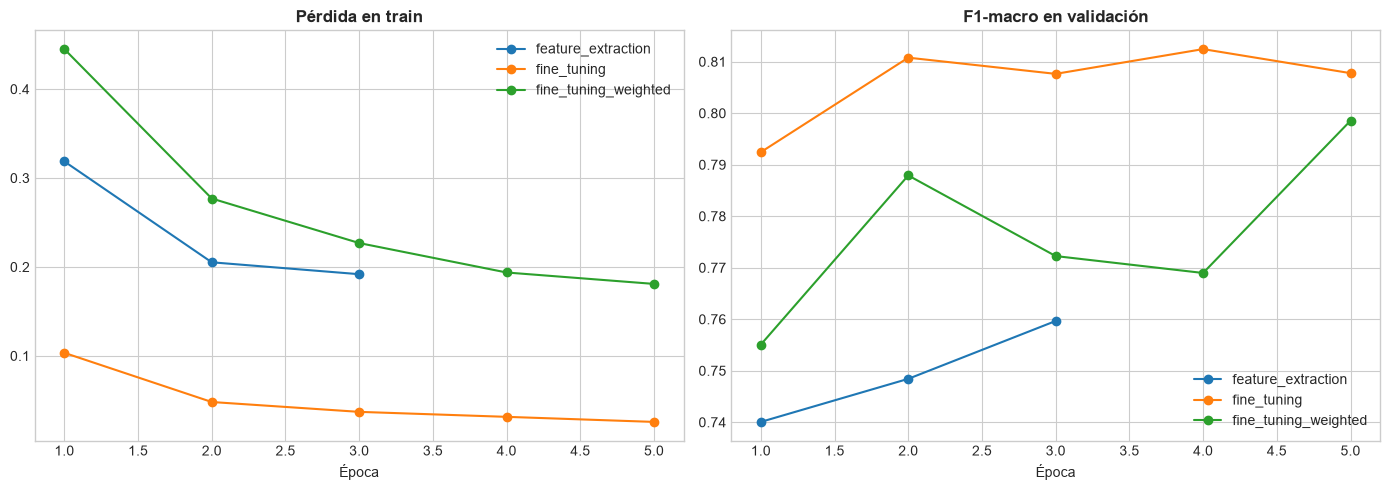

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, result in results.items():
    history = pd.DataFrame(result["history"])
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label=name)
    axes[1].plot(history["epoch"], history["val_f1_macro"], marker="o", label=name)

axes[0].set_title("Pérdida en train", fontweight="bold")
axes[1].set_title("F1-macro en validación", fontweight="bold")

for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()

plt.tight_layout()
plt.show()

El F1-macro es la media de las 5 clases, así que vemos también el F1 de cada clase en validación:

In [10]:
per_class_f1 = {}

for name, result in results.items():
    y_true_val, y_pred_val, _ = predict(result["model"], loaders["val"], device)
    per_class_f1[name] = f1_score(y_true_val, y_pred_val, average=None, zero_division=0)

pd.DataFrame(per_class_f1, index=classes).round(3)

,feature_extraction,fine_tuning,fine_tuning_weighted
Accessories,0.931,0.987,0.943
Apparel,0.974,0.997,0.992
Footwear,0.984,0.998,0.997
Other,0.000,0.095,0.123
Personal Care,0.909,0.984,0.938


## <a id='toc1_8_'></a>[Evaluación en test](#toc0_)

Elegimos el experimento con mejor F1-macro en validación y solo ahora lo evaluamos en test. Las métricas de test se guardan en el mismo run de MLflow.

In [11]:
best_name = comparison["val_f1_macro"].astype(float).idxmax()
best_model = results[best_name]["model"]

y_true, y_pred, y_prob = predict(best_model, loaders["test"], device)
test_metrics = compute_metrics(y_true, y_pred)

with mlflow.start_run(run_id=results[best_name]["run_id"]):
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})

print(f"Mejor experimento: {best_name}")
pd.Series(test_metrics).round(4)

Mejor experimento: fine_tuning


accuracy             0.9935
balanced_accuracy    0.8281
f1_macro             0.8457
dtype: float64

In [12]:
print(classification_report(y_true, y_pred, target_names=classes, digits=3, zero_division=0))

               precision    recall  f1-score   support

  Accessories      0.991     0.988     0.989      1610
      Apparel      0.997     0.999     0.998      3056
     Footwear      0.997     0.998     0.998      1317
        Other      0.750     0.158     0.261        19
Personal Care      0.969     0.997     0.983       343

     accuracy                          0.994      6345
    macro avg      0.941     0.828     0.846      6345
 weighted avg      0.993     0.994     0.993      6345



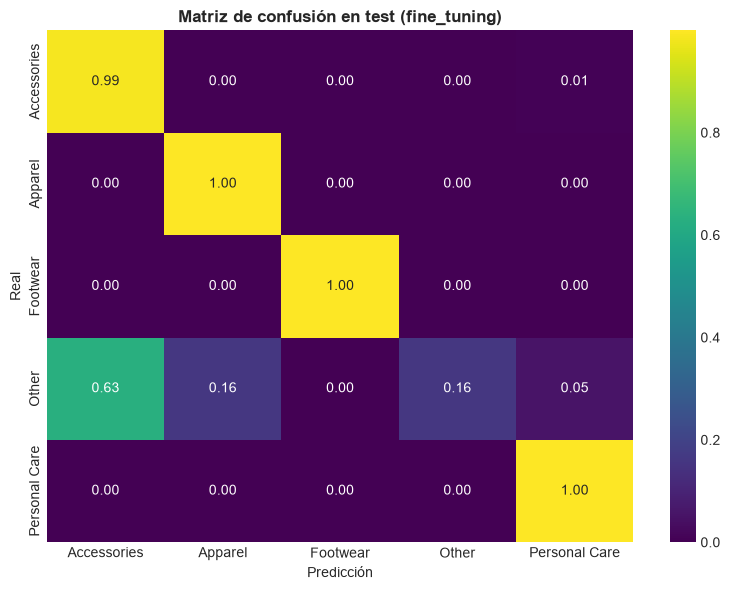

In [13]:
cm = confusion_matrix(y_true, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="viridis", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión en test ({best_name})", fontweight="bold")
plt.tight_layout()

with mlflow.start_run(run_id=results[best_name]["run_id"]):
    mlflow.log_figure(fig, "confusion_matrix_test.png")

plt.show()

Veamos qué imágenes de `Other` falla el modelo y qué predice para ellas:

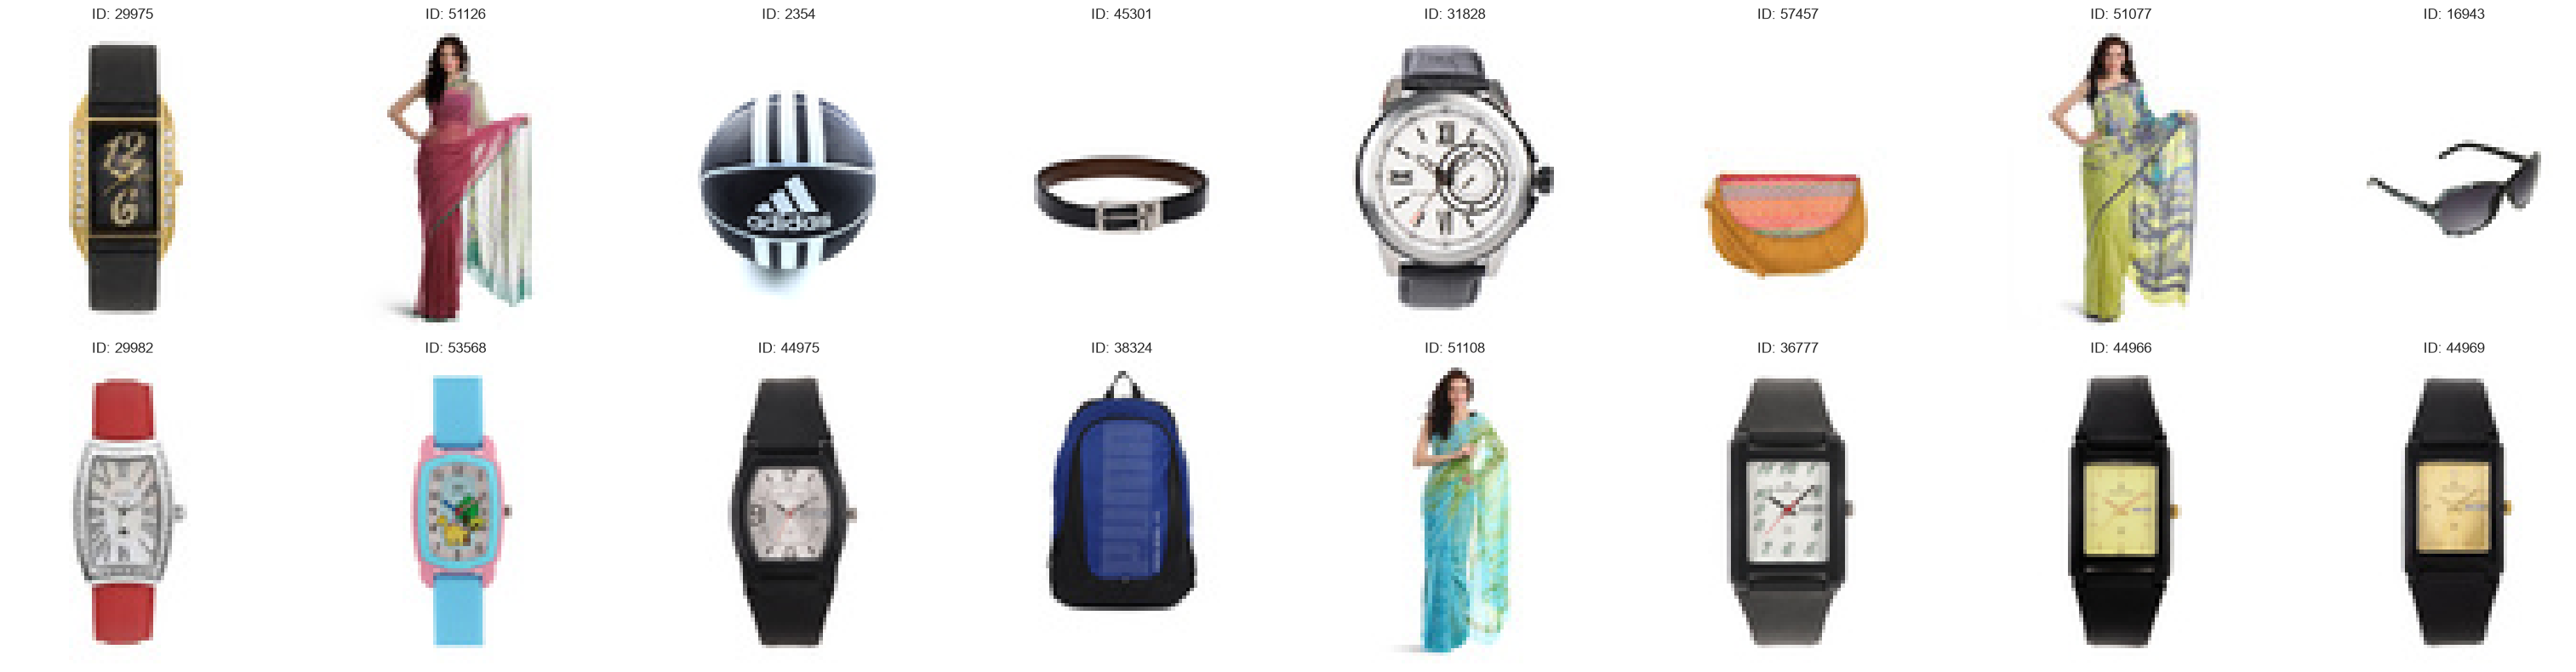

,id,masterCategory,articleType,productDisplayName,pred
1394,29975,Free Items,Free Gifts,Aspen Women Black Dial Watch,Accessories
9163,51126,Free Items,Free Gifts,Satya Paul Pink Saree,Apparel
9247,2354,Sporting Goods,Basketballs,ADIDAS Black Bounce Unisex Basketball,Personal Care
12443,45301,Free Items,Free Gifts,Van Heusen Men Black & Brown Reversible Belt,Accessories
16000,31828,Free Items,Free Gifts,Titan Men Off White Dial Watch,Accessories
16435,57457,Free Items,Free Gifts,Pitaraa Women Mustard Clutch,Accessories
17179,51077,Free Items,Free Gifts,Satya Paul Yellow Saree,Apparel
21134,16943,Free Items,Free Gifts,Image Women Black Sunglasses,Accessories
22758,29982,Free Items,Free Gifts,Aspen Women White Dial Watch,Accessories
23950,53568,Free Items,Free Gifts,Q&Q Kids Unisex White Dial Watch,Accessories


In [14]:
# El loader de test no baraja, así que las predicciones siguen el orden del DataFrame
test_df = df[df["split"] == "test"].assign(pred=[classes[i] for i in y_pred])
other_errors = test_df[(test_df["masterCategory_grouped"] == "Other") & (test_df["pred"] != "Other")]

show_images(ids=other_errors["id"], image_dir=IMAGES_DIR, n_cols=8)
other_errors[["id", "masterCategory", "articleType", "productDisplayName", "pred"]]

Casi todos los fallos son `Free Gifts` que visualmente son relojes, gafas, cinturones o bolsos (y el modelo dice `Accessories`) o saris (y dice `Apparel`). Es decir, el modelo no se equivoca tanto: `Free Items` indica que el producto es un regalo promocional, no qué aspecto tiene, y eso no se puede ver en la imagen.

## <a id='toc1_9_'></a>[Experimentos con más épocas](#toc0_)

Hasta ahora hemos entrenado con un número fijo de épocas. Las curvas muestran que el fine-tuning se estanca a partir de la época 2, pero la extracción de características y el fine-tuning con pesos todavía mejoraban en la última época. La idea era repetir los tres experimentos con **early stopping**: entrenar hasta un máximo de 30 épocas y parar si el F1-macro en validación no mejora en 3 épocas seguidas.

**Qué pasó:** al ejecutar estas celdas, el kernel tenía cargada una versión anterior de `fit` (de antes de añadir `patience`). En esa versión el octavo argumento era `start_epoch`, así que `PATIENCE = 3` se interpretó como "empezar a contar en la época 3": por eso las épocas van de 4 a 33 y **el early stopping no se aplicó**. Los tres experimentos entrenaron las 30 épocas completas, quedándose con la mejor en validación.

El entrenamiento es correcto, así que no los repetimos: en MLflow los hemos renombrado a `_30ep`, les hemos añadido una etiqueta que lo explica y hemos corregido `best_epoch`. Más abajo calculamos con su historial cuándo habría parado el early stopping.

In [19]:
MAX_EPOCHS = 30
PATIENCE = 3

### <a id='toc1_9_1_'></a>[Experimento 4: extracción de características (30 épocas)](#toc0_)

In [20]:
model = build_model(len(classes), freeze_backbone=True).to(device)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

run_experiment(
    "feature_extraction_es", model, optimizer, nn.CrossEntropyLoss(), MAX_EPOCHS,
    {"freeze_backbone": True, "lr": 1e-3, "class_weights": False}, patience=PATIENCE
)

Época 4: loss 0.3186 | val f1_macro 0.7401 | val balanced_acc 0.7339 | 79s
Época 5: loss 0.2052 | val f1_macro 0.7484 | val balanced_acc 0.7480 | 76s
Época 6: loss 0.1918 | val f1_macro 0.7597 | val balanced_acc 0.7639 | 87s
Época 7: loss 0.1841 | val f1_macro 0.7606 | val balanced_acc 0.7588 | 96s
Época 8: loss 0.1731 | val f1_macro 0.7593 | val balanced_acc 0.7542 | 101s
Época 9: loss 0.1719 | val f1_macro 0.7624 | val balanced_acc 0.7642 | 102s
Época 10: loss 0.1683 | val f1_macro 0.7601 | val balanced_acc 0.7573 | 98s
Época 11: loss 0.1638 | val f1_macro 0.7575 | val balanced_acc 0.7671 | 99s
Época 12: loss 0.1632 | val f1_macro 0.7588 | val balanced_acc 0.7575 | 100s
Época 13: loss 0.1632 | val f1_macro 0.7616 | val balanced_acc 0.7614 | 99s
Época 14: loss 0.1566 | val f1_macro 0.7563 | val balanced_acc 0.7634 | 99s
Época 15: loss 0.1627 | val f1_macro 0.7632 | val balanced_acc 0.7658 | 101s
Época 16: loss 0.1583 | val f1_macro 0.7646 | val balanced_acc 0.7657 | 110s
Época 17: los

2026/10/09 01:13:11 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


### <a id='toc1_9_2_'></a>[Experimento 5: fine-tuning (30 épocas)](#toc0_)

In [21]:
model = build_model(len(classes), freeze_backbone=False).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

run_experiment(
    "fine_tuning_es", model, optimizer, nn.CrossEntropyLoss(), MAX_EPOCHS,
    {"freeze_backbone": False, "lr": 1e-4, "class_weights": False}, patience=PATIENCE
)

Época 4: loss 0.1044 | val f1_macro 0.7935 | val balanced_acc 0.7958 | 302s
Época 5: loss 0.0475 | val f1_macro 0.7939 | val balanced_acc 0.7967 | 295s
Época 6: loss 0.0364 | val f1_macro 0.8101 | val balanced_acc 0.8050 | 299s
Época 7: loss 0.0326 | val f1_macro 0.8152 | val balanced_acc 0.8076 | 284s
Época 8: loss 0.0285 | val f1_macro 0.8101 | val balanced_acc 0.8052 | 302s
Época 9: loss 0.0216 | val f1_macro 0.8144 | val balanced_acc 0.8071 | 281s
Época 10: loss 0.0202 | val f1_macro 0.7835 | val balanced_acc 0.7976 | 278s
Época 11: loss 0.0191 | val f1_macro 0.8113 | val balanced_acc 0.8058 | 278s
Época 12: loss 0.0170 | val f1_macro 0.8196 | val balanced_acc 0.8161 | 289s
Época 13: loss 0.0157 | val f1_macro 0.8123 | val balanced_acc 0.8161 | 294s
Época 14: loss 0.0158 | val f1_macro 0.8061 | val balanced_acc 0.8053 | 280s
Época 15: loss 0.0125 | val f1_macro 0.8082 | val balanced_acc 0.8025 | 283s
Época 16: loss 0.0136 | val f1_macro 0.8120 | val balanced_acc 0.8077 | 271s
Época

2026/10/09 03:32:12 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


### <a id='toc1_9_3_'></a>[Experimento 6: fine-tuning con pesos de clase (30 épocas)](#toc0_)

In [22]:
weights = torch.tensor([class_weights[label] for label in classes], dtype=torch.float32).to(device)

model = build_model(len(classes), freeze_backbone=False).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

run_experiment(
    "fine_tuning_weighted_es", model, optimizer, nn.CrossEntropyLoss(weight=weights), MAX_EPOCHS,
    {"freeze_backbone": False, "lr": 1e-4, "class_weights": True}, patience=PATIENCE
)

Época 4: loss 0.4413 | val f1_macro 0.7537 | val balanced_acc 0.8310 | 269s
Época 5: loss 0.2753 | val f1_macro 0.7782 | val balanced_acc 0.8357 | 263s
Época 6: loss 0.2165 | val f1_macro 0.7891 | val balanced_acc 0.8132 | 264s
Época 7: loss 0.1861 | val f1_macro 0.7786 | val balanced_acc 0.8263 | 259s
Época 8: loss 0.1605 | val f1_macro 0.7950 | val balanced_acc 0.8415 | 268s
Época 9: loss 0.1281 | val f1_macro 0.7864 | val balanced_acc 0.8275 | 264s
Época 10: loss 0.1185 | val f1_macro 0.7846 | val balanced_acc 0.8476 | 261s
Época 11: loss 0.1278 | val f1_macro 0.7921 | val balanced_acc 0.8558 | 264s
Época 12: loss 0.1015 | val f1_macro 0.8222 | val balanced_acc 0.8369 | 1250s
Época 13: loss 0.1160 | val f1_macro 0.8053 | val balanced_acc 0.8479 | 398s
Época 14: loss 0.1115 | val f1_macro 0.8019 | val balanced_acc 0.8397 | 399s
Época 15: loss 0.0905 | val f1_macro 0.8057 | val balanced_acc 0.8475 | 399s
Época 16: loss 0.0692 | val f1_macro 0.8167 | val balanced_acc 0.8607 | 398s
Époc

2026/10/09 07:19:31 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


Época 33: loss 0.0403 | val f1_macro 0.8214 | val balanced_acc 0.8251 | 396s


### <a id='toc1_9_4_'></a>[Comparación de los seis experimentos](#toc0_)

Leemos de MLflow las mejores métricas de validación de todos los runs, también los de los experimentos 1-3, así no hace falta volver a ejecutarlos:

In [23]:
all_runs = mlflow.search_runs(
    experiment_names=["masterCategory"],
    filter_string="attributes.status = 'FINISHED'",
    order_by=["metrics.best_val_f1_macro DESC"],
)

all_runs[[
    "tags.mlflow.runName", "params.epochs", "params.patience", "metrics.epochs_trained", "metrics.best_epoch",
    "metrics.best_val_f1_macro", "metrics.best_val_balanced_accuracy", "metrics.best_val_accuracy",
]].round(4)

,tags.mlflow.runName,params.epochs,params.patience,metrics.epochs_trained,metrics.best_epoch,metrics.best_val_f1_macro,metrics.best_val_balanced_accuracy,metrics.best_val_accuracy
0,fine_tuning_es,30,3,30.0,31.0,0.8467,0.8389,0.9929
1,fine_tuning_weighted_es,30,3,30.0,17.0,0.8292,0.8547,0.9861
2,fine_tuning,5,NaN,NaN,NaN,0.8124,0.8064,0.9928
3,fine_tuning_weighted,5,NaN,NaN,NaN,0.7985,0.8628,0.9688
4,feature_extraction_es,30,3,30.0,28.0,0.7678,0.7689,0.9664
5,feature_extraction,3,NaN,NaN,NaN,0.7597,0.7639,0.9603


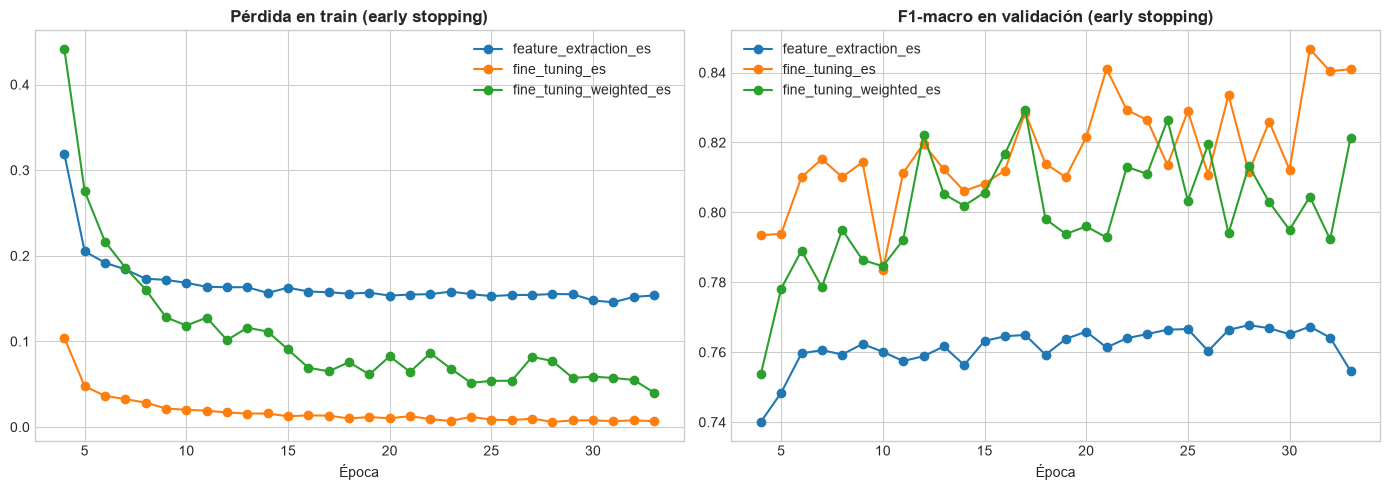

In [24]:
es_results = {name: result for name, result in results.items() if name.endswith("_es")}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, result in es_results.items():
    history = pd.DataFrame(result["history"])
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label=name)
    axes[1].plot(history["epoch"], history["val_f1_macro"], marker="o", label=name)

axes[0].set_title("Pérdida en train (early stopping)", fontweight="bold")
axes[1].set_title("F1-macro en validación (early stopping)", fontweight="bold")

for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()

plt.tight_layout()
plt.show()

F1 de cada clase en validación (experimentos 4-6):

In [25]:
per_class_f1_es = {}

for name, result in es_results.items():
    y_true_val, y_pred_val, _ = predict(result["model"], loaders["val"], device)
    per_class_f1_es[name] = f1_score(y_true_val, y_pred_val, average=None, zero_division=0)

pd.DataFrame(per_class_f1_es, index=classes).round(3)

,feature_extraction_es,fine_tuning_es,fine_tuning_weighted_es
Accessories,0.939,0.988,0.973
Apparel,0.978,0.999,0.996
Footwear,0.990,1.000,0.998
Other,0.000,0.276,0.197
Personal Care,0.932,0.972,0.981


### <a id='toc1_9_5_'></a>[¿Cuándo habría parado el early stopping?](#toc0_)

Como MLflow guarda el F1-macro de validación de cada época, podemos simular qué habría pasado con una paciencia de 3 sin volver a entrenar:

In [ ]:
client = mlflow.MlflowClient()
runs_30ep = mlflow.search_runs(experiment_names=["masterCategory"], filter_string="tags.mlflow.runName LIKE '%_30ep'")

simulation = {}

for _, run in runs_30ep.iterrows():
    history = sorted(client.get_metric_history(run["run_id"], "val_f1_macro"), key=lambda m: m.step)
    f1 = [m.value for m in history]

    # Early stopping con paciencia 3 sobre el historial guardado
    best, best_epoch, wait, stop_epoch = -1, 0, 0, len(f1)
    for epoch, value in enumerate(f1, start=1):
        if value > best:
            best, best_epoch, wait = value, epoch, 0
        else:
            wait += 1
        if wait >= 3:
            stop_epoch = epoch
            break

    simulation[run["tags.mlflow.runName"]] = {
        "mejor_f1_30_epocas": max(f1),
        "mejor_epoca_30": f1.index(max(f1)) + 1,
        "paraba_en_epoca": stop_epoch,
        "mejor_f1_con_paciencia_3": best,
        "mejor_epoca_paciencia_3": best_epoch,
    }

pd.DataFrame(simulation).T.round(4)

Con una paciencia de 3 los tres experimentos habrían parado entre las épocas 7 y 9, y se habrían perdido mejoras que llegaron más tarde (el fine-tuning pasa de 0,815 a 0,847). El F1-macro en validación sube y baja mucho de una época a otra por culpa de `Other` (19 imágenes), así que una paciencia tan corta para por ruido. Al final, que el early stopping no se aplicara nos ha venido bien.

Ojo: quedarnos con la mejor de 30 épocas ruidosas también infla un poco el resultado de validación (es como elegir la mejor de 30 tiradas). Por eso la cifra que cuenta es la de test, que calculamos en `05_mlflow`.

La elección del modelo final entre los seis experimentos (solo por validación) y su evaluación en test la hacemos en `05_mlflow`.

## <a id='toc1_10_'></a>[Modelos multitarea](#toc0_)

Hasta ahora solo predecimos `masterCategory`. Ahora entrenamos **una sola red que predice a la vez** `masterCategory`, `subCategory` y `articleType`: la ResNet18 se comparte entre las tres tareas y cada una tiene su propia capa de salida. La pérdida es la suma de las tres.

Así la app puede dar mucho más detalle ("Accessories → Watches → Watches" en lugar de solo "Accessories"), y podemos ver si aprender las tres tareas juntas ayuda o perjudica a `masterCategory` (aprendizaje multitarea, Caruana 1997; en moda, DeepFashion también aprende categorías y atributos a la vez).

Usamos el mismo split y la configuración del mejor modelo de una tarea (fine-tuning, lr 1e-4, 30 épocas). Nos quedamos con la época con mejor **media del F1-macro de las tres tareas** en validación. Los runs van a un experimento nuevo de MLflow, `multitask`.

In [ ]:
# Experimento nuevo de MLflow para los modelos multitarea
setup_mlflow(experiment_name="multitask")

TASKS = ["masterCategory", "subCategory", "articleType"]
MIN_TRAIN_EXAMPLES = 100   # clases con menos imágenes en train se agrupan en "Other"
MT_EPOCHS = 30
MT_LR = 1e-4

### <a id='toc1_10_1_'></a>[Etiquetas](#toc0_)

`subCategory` y `articleType` tienen muchas clases con muy pocos ejemplos. Igual que hicimos con `masterCategory`, agrupamos en `Other` las clases con menos de 100 imágenes **en train** (contamos solo en train para no usar información de val/test). `masterCategory` mantiene sus 5 clases de siempre.

In [7]:
mt_df, mt_label_mappings = build_multitask_labels(
    pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv"), tasks=TASKS, min_count=MIN_TRAIN_EXAMPLES
)

pd.DataFrame({
    "n_clases": {task: len(mt_label_mappings[task]) for task in TASKS},
    "% en Other": {task: (mt_df[f"{task}_mt"] == "Other").mean() * 100 for task in TASKS},
}).round(2)

,n_clases,% en Other
masterCategory,5,0.29
subCategory,23,2.27
articleType,50,6.37


### <a id='toc1_10_2_'></a>[Experimento 7](#toc0_)

Entrenamos y registramos en MLflow los parámetros, las métricas de cada tarea por época, las mejores métricas, los mapeos de clases y el modelo:

In [ ]:
mt_loaders = make_loaders(
    mt_df, IMAGES_DIR, label_col=[f"{task}_idx_mt" for task in TASKS],
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
)

mt_model = MultiTaskResNet(
    num_classes={task: len(mt_label_mappings[task]) for task in TASKS}, freeze_backbone=False
).to(device)
mt_optimizer = torch.optim.Adam(mt_model.parameters(), lr=MT_LR)

with mlflow.start_run(run_name="multitask_fine_tuning_30ep") as mt_run:
    mlflow.log_params({
        "architecture": "resnet18_multitask",
        "tasks": ",".join(TASKS),
        "min_train_examples": MIN_TRAIN_EXAMPLES,
        **{f"n_classes_{task}": len(mt_label_mappings[task]) for task in TASKS},
        "image_size": str(IMAGE_SIZE),
        "batch_size": BATCH_SIZE,
        "epochs": MT_EPOCHS,
        "lr": MT_LR,
        "freeze_backbone": False,
    })

    mt_history = fit_multitask(
        model=mt_model, train_loader=mt_loaders["train"], val_loader=mt_loaders["val"],
        criterion=nn.CrossEntropyLoss(), optimizer=mt_optimizer, device=device,
        epochs=MT_EPOCHS, tasks=TASKS,
    )

    # Mejores métricas de validación (fit_multitask deja en el modelo los pesos de esa época)
    mt_best = max(mt_history, key=lambda h: h["val_f1_macro_mean"])
    mlflow.log_metrics({f"best_{k}": v for k, v in mt_best.items() if k.startswith("val_")})
    mlflow.log_metrics({"best_epoch": mt_best["epoch"], "epochs_trained": len(mt_history)})

    mlflow.log_dict(mt_label_mappings, "label_mappings.json")
    mlflow.pytorch.log_model(mt_model.to("cpu"), name="model", serialization_format="pickle")
    mt_model.to(device)

print(f"Mejor época: {mt_best['epoch']} | F1-macro medio en validación: {mt_best['val_f1_macro_mean']:.4f}")

Época 1: loss 1.4925 | val F1-macro: masterCategory 0.7880 | subCategory 0.8928 | articleType 0.7396 | media 0.8068 | 226s
Época 2: loss 0.6696 | val F1-macro: masterCategory 0.8127 | subCategory 0.9095 | articleType 0.7879 | media 0.8367 | 255s
Época 3: loss 0.5412 | val F1-macro: masterCategory 0.8150 | subCategory 0.9167 | articleType 0.8073 | media 0.8463 | 261s
Época 4: loss 0.4616 | val F1-macro: masterCategory 0.8128 | subCategory 0.9116 | articleType 0.8308 | media 0.8517 | 260s
Época 5: loss 0.4039 | val F1-macro: masterCategory 0.8156 | subCategory 0.9299 | articleType 0.8303 | media 0.8586 | 265s
Época 6: loss 0.3529 | val F1-macro: masterCategory 0.8292 | subCategory 0.9174 | articleType 0.8253 | media 0.8573 | 269s
Época 7: loss 0.3192 | val F1-macro: masterCategory 0.8122 | subCategory 0.9322 | articleType 0.8534 | media 0.8659 | 276s
Época 8: loss 0.2792 | val F1-macro: masterCategory 0.8261 | subCategory 0.9320 | articleType 0.8460 | media 0.8680 | 273s
Época 9: loss 0.

2026/10/09 16:48:21 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


Mejor época: 19 | F1-macro medio en validación: 0.8783


### <a id='toc1_10_3_'></a>[Resultados](#toc0_)

Evolución del F1-macro de cada tarea en validación:

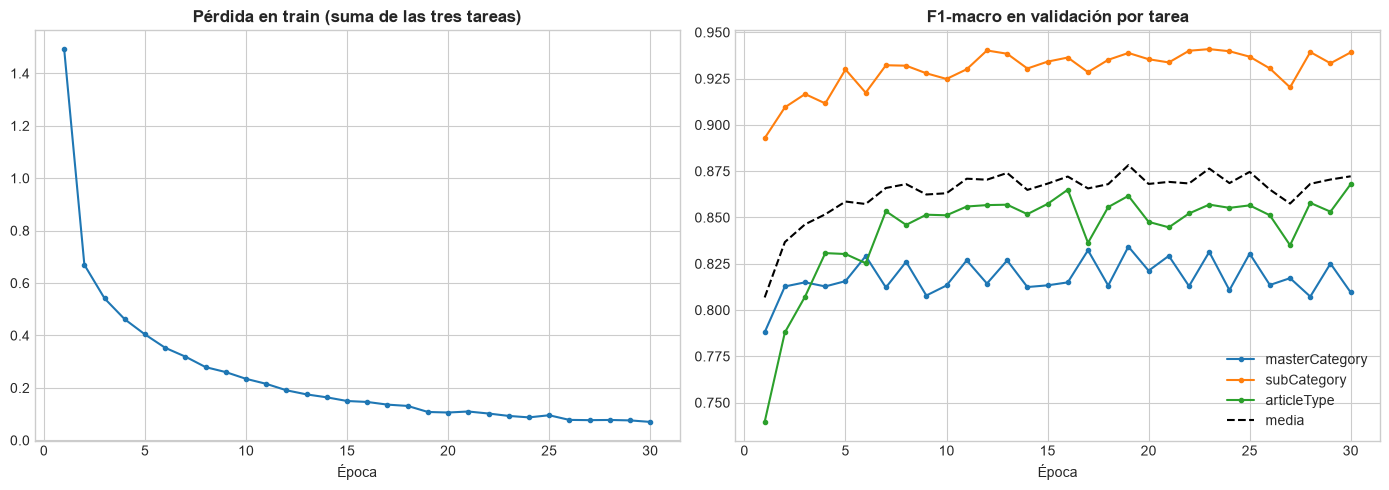

In [9]:
mt_hist = pd.DataFrame(mt_history)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(mt_hist["epoch"], mt_hist["train_loss"], marker="o", markersize=3)
axes[0].set_title("Pérdida en train (suma de las tres tareas)", fontweight="bold")

for task in TASKS:
    axes[1].plot(mt_hist["epoch"], mt_hist[f"val_{task}_f1_macro"], marker="o", markersize=3, label=task)
axes[1].plot(mt_hist["epoch"], mt_hist["val_f1_macro_mean"], linestyle="--", color="black", label="media")
axes[1].set_title("F1-macro en validación por tarea", fontweight="bold")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Época")

plt.tight_layout()
plt.show()

Métricas de la mejor época, y comparación de `masterCategory` con el mejor modelo de una sola tarea (`fine_tuning_30ep`, que leemos de MLflow):

In [10]:
mt_summary = pd.DataFrame({
    task: {metric: mt_best[f"val_{task}_{metric}"] for metric in ["accuracy", "balanced_accuracy", "f1_macro"]}
    for task in TASKS
}).T

single_task = mlflow.search_runs(
    experiment_names=["masterCategory"], filter_string="tags.mlflow.runName = 'fine_tuning_30ep'"
).iloc[0]
mt_summary.loc["masterCategory (modelo de una tarea)"] = [
    single_task["metrics.best_val_accuracy"],
    single_task["metrics.best_val_balanced_accuracy"],
    single_task["metrics.best_val_f1_macro"],
]

print(f"Mejor época: {mt_best['epoch']}")
mt_summary.round(4)

Mejor época: 19


,accuracy,balanced_accuracy,f1_macro
masterCategory,0.9932,0.8280,0.8343
subCategory,0.9680,0.9384,0.9389
articleType,0.8939,0.8618,0.8617
masterCategory (modelo de una tarea),0.9929,0.8389,0.8467


`articleType` es la tarea más difícil (50 clases). Vemos los tipos de artículo que mejor y peor reconoce en validación:

In [11]:
mt_true, mt_pred = predict_multitask(mt_model, mt_loaders["val"], device, TASKS)

article_classes = sorted(mt_label_mappings["articleType"], key=mt_label_mappings["articleType"].get)
article_f1 = pd.Series(
    f1_score(mt_true["articleType"], mt_pred["articleType"], labels=range(len(article_classes)), average=None, zero_division=0),
    index=article_classes,
).sort_values()

val_support = mt_df.loc[mt_df["split"] == "val", "articleType_mt"].value_counts()
article_table = pd.DataFrame({"f1": article_f1, "imagenes_val": val_support.reindex(article_f1.index)})

pd.concat([article_table.head(10), article_table.tail(10)]).round(3)

,f1,imagenes_val
Tunics,0.358,22
Flats,0.518,84
Kurtis,0.559,40
Sweaters,0.667,35
Jackets,0.667,36
Sweatshirts,0.687,35
Tops,0.724,227
Capris,0.737,30
Leggings,0.762,19
Heels,0.778,192


La mejor época es la 19, con un F1-macro medio de 0,878 en validación:
- **`subCategory`** (23 clases): F1-macro 0,939.
- **`articleType`** (50 clases): F1-macro 0,862. Con 50 clases es un resultado muy bueno.
- **`masterCategory`**: F1-macro 0,834, frente a 0,847 del modelo de una sola tarea. La diferencia (0,013) es del tamaño del ruido que mete `Other` (acertar o fallar una sola de sus 19 imágenes mueve el F1-macro 0,01-0,02), y la accuracy es la misma (0,993). Es decir, **compartir la red con las otras dos tareas no empeora `masterCategory`** y a cambio el modelo nos da mucho más detalle.

Los tipos de artículo que peor reconoce son prendas que se parecen mucho entre sí, incluso para una persona. Las confusiones más frecuentes en validación son:
- Zapatillas deportivas ↔ zapatillas casual (72 + 16) y zapatos casual → formales (16).
- Tacones ↔ bailarinas (44 + 23): con imágenes de 60x80 la altura del tacón a veces no se ve.
- Tops ↔ camisetas (38 + 29) y tops → camisas (12).
- Kurtas, kurtis y túnicas entre sí.

Los que mejor reconoce son productos con una forma muy característica: relojes, gafas de sol, corbatas, cinturones, pintalabios o esmaltes de uñas (F1 ≥ 0,97).

La evaluación en test y el registro del modelo multitarea en el Model Registry los haremos en `05_mlflow`.

### <a id='toc1_10_4_'></a>[Modelo multitarea: color y género](#toc0_)

Añadimos dos salidas más al modelo multitarea: el **color** (`baseColour`) y el **género** (`gender`). Son atributos básicos para una futura función de la app que combine prendas y proponga *looks* (no mezclar dos pantalones, combinar colores que casen, no mezclar ropa de hombre y de mujer), y además permiten buscar productos parecidos del mismo color.

El color es una tarea más difícil y con más ruido: hay muchos nombres parecidos (`Blue` y `Navy Blue`, `Grey` y `Grey Melange`) y la red ha aprendido sobre todo formas. Igual que antes, agrupamos en `Other` las clases con menos de 100 imágenes en train. Mantenemos la misma configuración que en el multitarea v1 para que la comparación sea justa.


#### <a id='toc1_10_4_1_'></a>[Etiquetas](#toc0_)

Las del v1 más el color y el género, con la misma función y el mismo mínimo de 100 imágenes en train:

In [8]:
TASKS_V2 = ["masterCategory", "subCategory", "articleType", "baseColour", "gender"]

v2_df, v2_label_mappings = build_multitask_labels(
    pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv"), tasks=TASKS_V2, min_count=MIN_TRAIN_EXAMPLES
)

pd.DataFrame({
    "n_clases": {task: len(v2_label_mappings[task]) for task in TASKS_V2},
    "% en Other": {task: (v2_df[f"{task}_mt"] == "Other").mean() * 100 for task in TASKS_V2},
}).round(2)

,n_clases,% en Other
masterCategory,5,0.29
subCategory,23,2.27
articleType,50,6.37
baseColour,28,2.33
gender,5,0.00


#### <a id='toc1_10_4_2_'></a>[Experimento 8](#toc0_)

In [ ]:
v2_loaders = make_loaders(
    v2_df, IMAGES_DIR, label_col=[f"{task}_idx_mt" for task in TASKS_V2],
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
)

v2_model = MultiTaskResNet(
    num_classes={task: len(v2_label_mappings[task]) for task in TASKS_V2}, freeze_backbone=False
).to(device)
v2_optimizer = torch.optim.Adam(v2_model.parameters(), lr=MT_LR)

with mlflow.start_run(run_name="multitask_v2_fine_tuning_30ep") as v2_run:
    mlflow.log_params({
        "architecture": "resnet18_multitask",
        "tasks": ",".join(TASKS_V2),
        "min_train_examples": MIN_TRAIN_EXAMPLES,
        **{f"n_classes_{task}": len(v2_label_mappings[task]) for task in TASKS_V2},
        "image_size": str(IMAGE_SIZE),
        "batch_size": BATCH_SIZE,
        "epochs": MT_EPOCHS,
        "lr": MT_LR,
        "freeze_backbone": False,
    })

    v2_history = fit_multitask(
        model=v2_model, train_loader=v2_loaders["train"], val_loader=v2_loaders["val"],
        criterion=nn.CrossEntropyLoss(), optimizer=v2_optimizer, device=device,
        epochs=MT_EPOCHS, tasks=TASKS_V2,
    )

    # Mejores métricas de validación (fit_multitask deja en el modelo los pesos de esa época)
    v2_best = max(v2_history, key=lambda h: h["val_f1_macro_mean"])
    mlflow.log_metrics({f"best_{k}": v for k, v in v2_best.items() if k.startswith("val_")})
    mlflow.log_metrics({"best_epoch": v2_best["epoch"], "epochs_trained": len(v2_history)})

    mlflow.log_dict(v2_label_mappings, "label_mappings.json")
    mlflow.pytorch.log_model(v2_model.to("cpu"), name="model", serialization_format="pickle")
    v2_model.to(device)

print(f"Mejor época: {v2_best['epoch']} | F1-macro medio en validación: {v2_best['val_f1_macro_mean']:.4f}")

Época 1: loss 3.7626 | val F1-macro: masterCategory 0.7903 | subCategory 0.8679 | articleType 0.7117 | baseColour 0.3615 | gender 0.7166 | media 0.6896 | 228s
Época 2: loss 2.2379 | val F1-macro: masterCategory 0.7898 | subCategory 0.9042 | articleType 0.7816 | baseColour 0.3927 | gender 0.7032 | media 0.7143 | 242s
Época 3: loss 1.9120 | val F1-macro: masterCategory 0.7926 | subCategory 0.9074 | articleType 0.8018 | baseColour 0.4544 | gender 0.7557 | media 0.7424 | 251s
Época 4: loss 1.7118 | val F1-macro: masterCategory 0.8121 | subCategory 0.9124 | articleType 0.7992 | baseColour 0.4802 | gender 0.7622 | media 0.7532 | 252s
Época 5: loss 1.5587 | val F1-macro: masterCategory 0.7908 | subCategory 0.9144 | articleType 0.8154 | baseColour 0.4774 | gender 0.7678 | media 0.7531 | 246s
Época 6: loss 1.4365 | val F1-macro: masterCategory 0.8114 | subCategory 0.9191 | articleType 0.8323 | baseColour 0.4652 | gender 0.7333 | media 0.7523 | 248s
Época 7: loss 1.3154 | val F1-macro: masterCat

2026/10/10 18:16:47 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


Mejor época: 27 | F1-macro medio en validación: 0.7832


#### <a id='toc1_10_4_3_'></a>[Resultados](#toc0_)

Evolución del F1-macro de cada tarea en validación:

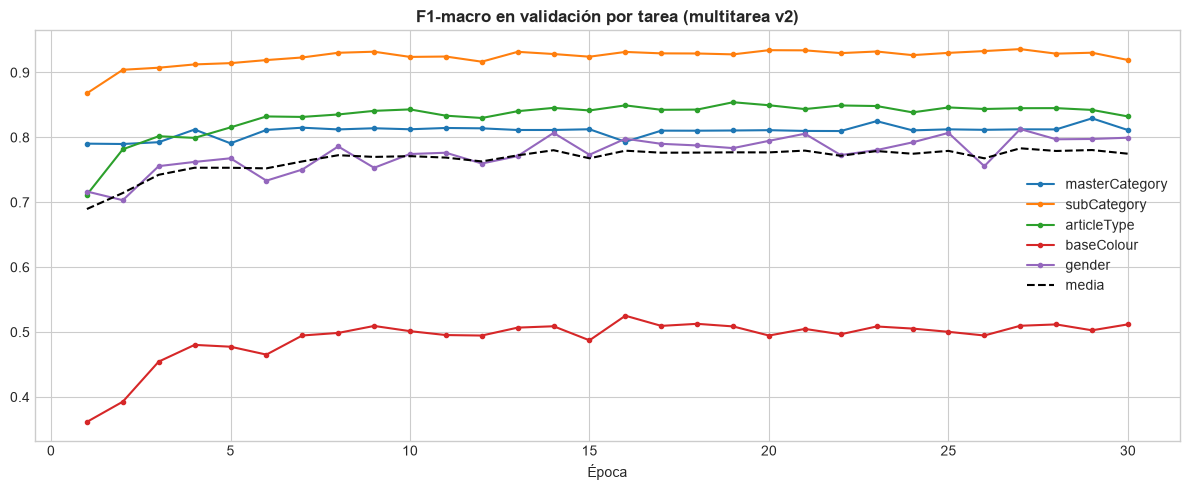

In [5]:
v2_hist = pd.DataFrame(v2_history)

fig, ax = plt.subplots(figsize=(12, 5))
for task in TASKS_V2:
    ax.plot(v2_hist["epoch"], v2_hist[f"val_{task}_f1_macro"], marker="o", markersize=3, label=task)
ax.plot(v2_hist["epoch"], v2_hist["val_f1_macro_mean"], linestyle="--", color="black", label="media")
ax.set_xlabel("Época")
ax.set_title("F1-macro en validación por tarea (multitarea v2)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

Comparamos con el multitarea v1 en las tareas comunes (mejor época de cada uno, en validación):

In [6]:
v1_run = mlflow.search_runs(
    experiment_names=["multitask"], filter_string="tags.mlflow.runName = 'multitask_fine_tuning_30ep'"
).iloc[0]

v2_vs_v1 = pd.DataFrame({
    task: {
        "v1 (3 tareas)": v1_run.get(f"metrics.best_val_{task}_f1_macro"),
        "v2 (5 tareas)": v2_best[f"val_{task}_f1_macro"],
    }
    for task in TASKS_V2
}).T

print(f"Mejor época v2: {v2_best['epoch']}")
v2_vs_v1.round(4)

Mejor época v2: 27


,v1 (3 tareas),v2 (5 tareas)
masterCategory,0.8343,0.8124
subCategory,0.9389,0.9360
articleType,0.8617,0.8450
baseColour,NaN,0.5097
gender,NaN,0.8128


Colores que mejor y peor reconoce en validación, y las confusiones más frecuentes:

In [7]:
v2_true, v2_pred = predict_multitask(v2_model, v2_loaders["val"], device, TASKS_V2)

colour_classes = sorted(v2_label_mappings["baseColour"], key=v2_label_mappings["baseColour"].get)
colour_f1 = pd.Series(
    f1_score(v2_true["baseColour"], v2_pred["baseColour"], labels=range(len(colour_classes)), average=None, zero_division=0),
    index=colour_classes,
).sort_values()
colour_support = v2_df.loc[v2_df["split"] == "val", "baseColour_mt"].value_counts()
display(pd.DataFrame({"f1": colour_f1, "imagenes_val": colour_support.reindex(colour_f1.index)}).round(3))

colour_confusions = Counter(
    (colour_classes[t], colour_classes[p]) for t, p in zip(v2_true["baseColour"], v2_pred["baseColour"]) if t != p
)
pd.DataFrame(colour_confusions.most_common(12), columns=["real -> predicho", "n"])

,f1,imagenes_val
Off White,0.174,30
Other,0.214,171
Cream,0.283,54
Peach,0.286,27
Charcoal,0.298,32
Grey Melange,0.320,15
Beige,0.372,103
Khaki,0.375,23
Maroon,0.389,80
Multi,0.419,61


,real -> predicho,n
0,"(Blue, Navy Blue)",112
1,"(Black, Navy Blue)",70
2,"(Grey, Black)",62
3,"(Black, Grey)",56
4,"(Navy Blue, Blue)",53
5,"(Brown, Black)",49
6,"(Silver, White)",44
7,"(Other, Brown)",41
8,"(Grey, White)",38
9,"(Grey, Navy Blue)",26


La mejor época es la 27 (F1-macro medio 0,783 en validación; la media es más baja que en el v1 porque ahora incluye el color, que es la tarea más difícil):
- **Género** (5 clases): F1-macro 0,813 y accuracy 0,927. Casi todos los errores son entre hombre, mujer y unisex (por ejemplo, 144 productos de mujer que predice como de hombre); los productos de niño y niña apenas se confunden con los de adulto. Muchos accesorios, relojes o zapatillas son prácticamente iguales para hombre y mujer, así que es normal.
- **Color** (28 clases): F1-macro 0,510 y accuracy 0,664. Es la tarea más difícil, y la mayoría de errores son entre colores muy parecidos o con nombres ambiguos: azul ↔ azul marino (112 + 53), negro ↔ gris (56 + 62), negro → azul marino (70), marrón → negro (49), plateado → blanco (44) o granate → rojo (25). Los colores básicos los reconoce bastante bien (negro 0,81, blanco 0,75, amarillo 0,75, rojo 0,74, azul 0,72) y los que peor son los tonos claros o mezclados (`Off White`, `Cream`, `Peach`, `Grey Melange`, `Multi`).
- **Tareas del v1**: añadir el color y el género empeora un poco las otras tres (`articleType` 0,845 frente a 0,862, `subCategory` 0,936 frente a 0,939 y `masterCategory` 0,812 frente a 0,834, esta última dentro del ruido de `Other`). La red tiene que repartir su capacidad entre más tareas, y el color "tira" en otra dirección que la forma.

Es decir, ganamos dos atributos nuevos (útiles para la app y para recomendar *looks*) a cambio de perder un poco en el tipo de artículo. Con imágenes de 60x80 y nombres de color tan ambiguos, un F1 de 0,51 en color es un resultado razonable, pero hay que tomarlo con cuidado en la app.

La evaluación en test y el registro de este modelo los haremos en `05_mlflow`.

### <a id='toc1_10_5_'></a>[Modelo multitarea: género sin color](#toc0_)

En el modelo anterior (v2), al añadir el color y el género, el tipo de artículo empeoró un poco. Para saber **si la culpa es del color o simplemente de tener más tareas**, entrenamos este modelo (v3) con las tres tareas del primer modelo multitask (v1) más el género, pero **sin el color**, con la misma configuración. Es un experimento de control (*ablation*): solo cambia una cosa respecto al v2.

- Si el v3 recupera el tipo de artículo del v1, la pérdida del v2 la provoca el color.
- Si no lo recupera, la pérdida viene de añadir tareas en general.

Este modelo es solo para el análisis: la app sigue usando el v2.

#### <a id='toc1_10_5_1_'></a>[Etiquetas](#toc0_)

Las mismas que en el v2, sin el color:

In [12]:
TASKS_V3 = ["masterCategory", "subCategory", "articleType", "gender"]

v3_df, v3_label_mappings = build_multitask_labels(
    pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv"), tasks=TASKS_V3, min_count=MIN_TRAIN_EXAMPLES
)

pd.DataFrame({
    "n_clases": {task: len(v3_label_mappings[task]) for task in TASKS_V3},
    "% en Other": {task: (v3_df[f"{task}_mt"] == "Other").mean() * 100 for task in TASKS_V3},
}).round(2)

,n_clases,% en Other
masterCategory,5,0.29
subCategory,23,2.27
articleType,50,6.37
gender,5,0.00


#### <a id='toc1_10_5_2_'></a>[Experimento 9](#toc0_)

In [3]:
v3_loaders = make_loaders(
    v3_df, IMAGES_DIR, label_col=[f"{task}_idx_mt" for task in TASKS_V3],
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
)

v3_model = MultiTaskResNet(
    num_classes={task: len(v3_label_mappings[task]) for task in TASKS_V3}, freeze_backbone=False
).to(device)
v3_optimizer = torch.optim.Adam(v3_model.parameters(), lr=MT_LR)

with mlflow.start_run(run_name="multitask_v3_fine_tuning_30ep") as v3_run:
    mlflow.log_params({
        "architecture": "resnet18_multitask",
        "tasks": ",".join(TASKS_V3),
        "min_train_examples": MIN_TRAIN_EXAMPLES,
        **{f"n_classes_{task}": len(v3_label_mappings[task]) for task in TASKS_V3},
        "image_size": str(IMAGE_SIZE),
        "batch_size": BATCH_SIZE,
        "epochs": MT_EPOCHS,
        "lr": MT_LR,
        "freeze_backbone": False,
    })

    v3_history = fit_multitask(
        model=v3_model, train_loader=v3_loaders["train"], val_loader=v3_loaders["val"],
        criterion=nn.CrossEntropyLoss(), optimizer=v3_optimizer, device=device,
        epochs=MT_EPOCHS, tasks=TASKS_V3,
    )

    # Mejores métricas de validación (fit_multitask deja en el modelo los pesos de esa época)
    v3_best = max(v3_history, key=lambda h: h["val_f1_macro_mean"])
    mlflow.log_metrics({f"best_{k}": v for k, v in v3_best.items() if k.startswith("val_")})
    mlflow.log_metrics({"best_epoch": v3_best["epoch"], "epochs_trained": len(v3_history)})

    mlflow.log_dict(v3_label_mappings, "label_mappings.json")
    mlflow.pytorch.log_model(v3_model.to("cpu"), name="model", serialization_format="pickle")
    v3_model.to(device)

print(f"Mejor época: {v3_best['epoch']} | F1-macro medio en validación: {v3_best['val_f1_macro_mean']:.4f}")

Época 1: loss 1.9875 | val F1-macro: masterCategory 0.7917 | subCategory 0.8838 | articleType 0.7424 | gender 0.7040 | media 0.7805 | 249s
Época 2: loss 1.0017 | val F1-macro: masterCategory 0.7955 | subCategory 0.9119 | articleType 0.7953 | gender 0.7455 | media 0.8121 | 256s
Época 3: loss 0.8037 | val F1-macro: masterCategory 0.8144 | subCategory 0.9181 | articleType 0.8236 | gender 0.7686 | media 0.8312 | 251s
Época 4: loss 0.6943 | val F1-macro: masterCategory 0.8311 | subCategory 0.9297 | articleType 0.8367 | gender 0.7232 | media 0.8302 | 246s
Época 5: loss 0.6026 | val F1-macro: masterCategory 0.8088 | subCategory 0.9267 | articleType 0.8242 | gender 0.7823 | media 0.8355 | 247s
Época 6: loss 0.5403 | val F1-macro: masterCategory 0.8154 | subCategory 0.9317 | articleType 0.8482 | gender 0.7903 | media 0.8464 | 264s
Época 7: loss 0.4825 | val F1-macro: masterCategory 0.8116 | subCategory 0.9315 | articleType 0.8456 | gender 0.7868 | media 0.8439 | 274s
Época 8: loss 0.4382 | val 

2026/10/10 23:39:29 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


Mejor época: 17 | F1-macro medio en validación: 0.8642


Evolución del F1-macro de cada tarea en validación:

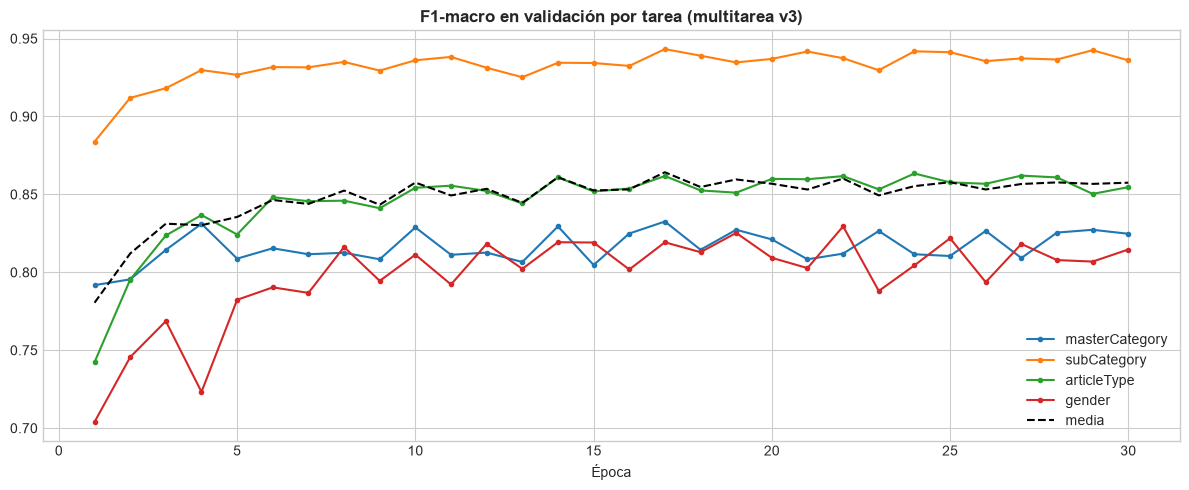

In [6]:
v3_hist = pd.DataFrame(v3_history)

fig, ax = plt.subplots(figsize=(12, 5))
for task in TASKS_V3:
    ax.plot(v3_hist["epoch"], v3_hist[f"val_{task}_f1_macro"], marker="o", markersize=3, label=task)
ax.plot(v3_hist["epoch"], v3_hist["val_f1_macro_mean"], linestyle="--", color="black", label="media")
ax.set_xlabel("Época")
ax.set_title("F1-macro en validación por tarea (multitarea v3)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

#### <a id='toc1_10_5_3_'></a>[Resultados](#toc0_)

F1-macro en validación (mejor época de cada modelo) en las tareas de cada uno:

In [9]:
multitask_runs = {
    name: mlflow.search_runs(experiment_names=["multitask"], filter_string=f"tags.mlflow.runName = '{run_name}'").iloc[0]
    for name, run_name in [
        ("v1 (3 tareas)", "multitask_fine_tuning_30ep"),
        ("v2 (5 tareas)", "multitask_v2_fine_tuning_30ep"),
        ("v3 (sin color)", "multitask_v3_fine_tuning_30ep"),
    ]
}

multitask_comparison = pd.DataFrame({
    name: {task: run.get(f"metrics.best_val_{task}_f1_macro") for task in TASKS_V2}
    for name, run in multitask_runs.items()
})

multitask_comparison.round(4)

,v1 (3 tareas),v2 (5 tareas),v3 (sin color)
masterCategory,0.8343,0.8124,0.8326
subCategory,0.9389,0.9360,0.9432
articleType,0.8617,0.8450,0.8618
baseColour,NaN,0.5097,NaN
gender,NaN,0.8128,0.8192


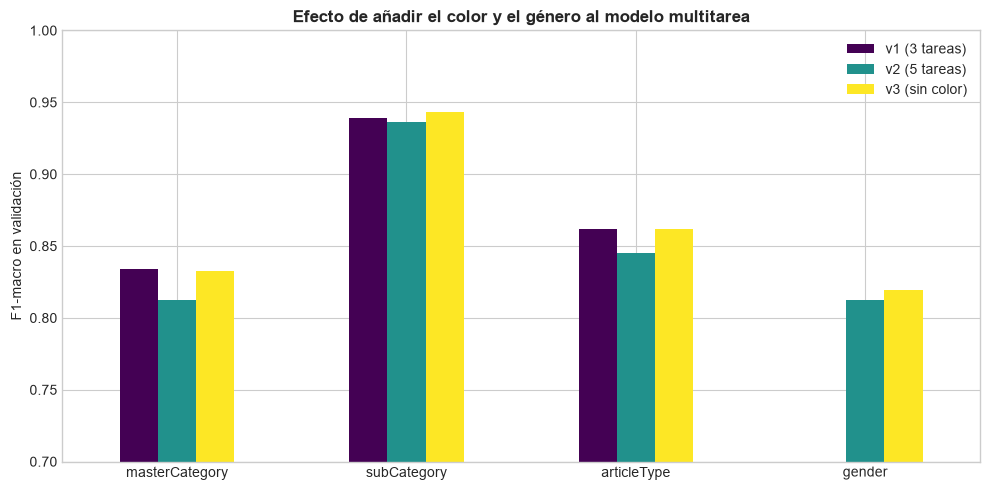

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
multitask_comparison.loc[TASKS_V3].plot(kind="bar", ax=ax, rot=0, colormap="viridis")
ax.set_ylim(0.7, 1.0)
ax.set_ylabel("F1-macro en validación")
ax.set_title("Efecto de añadir el color y el género al modelo multitarea", fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

La mejor época del v3 es la 17 (F1-macro medio 0,864 en validación):
- **Tipo de artículo**: 0,862, igual que el v1 (0,862) y por encima del v2 (0,845). Al quitar el color **recupera todo lo que perdía el v2**.
- **Subcategoría**: 0,943, incluso algo mejor que el v1 (0,939) y el v2 (0,936).
- **Categoría**: 0,833, igual que el v1 (0,834). El v2 bajaba a 0,812, aunque esa tarea está dentro del ruido de `Other`.
- **Género**: 0,819, un poco mejor que en el v2 (0,813).

Es decir, la pérdida del v2 **no viene de tener más tareas, sino del color**. El género se fija, igual que el tipo, en la forma del producto, y aprenderlos juntos no molesta. El color en cambio necesita otras características (el tono, no la silueta) y compite con el resto de tareas por la misma red: es un caso de **transferencia negativa** entre tareas.

Hay que tomarlo con cautela, porque cada modelo se ha entrenado una sola vez (una semilla) y las diferencias son pequeñas. Aun así, el patrón es coherente en las tres tareas comunes.

Para la app nos quedamos con el v2, porque el color es útil para buscar productos parecidos y para los futuros *looks*. Una mejora para el futuro sería predecir el color con un modelo aparte, para no penalizar el tipo de artículo.

## <a id='toc1_11_'></a>[Resumen](#toc0_)

- **Extracción de características** (red congelada): F1-macro 0,760 en validación. Funciona, pero las características de ImageNet no bastan para nuestras imágenes.
- **Fine-tuning**: el mejor de los tres primeros experimentos, F1-macro 0,812 en validación. Mejora todas las clases respecto al anterior.
- **Fine-tuning con pesos de clase**: sube el recall de `Other` pero empieza a confundir muchos accesorios con `Other`, así que el F1-macro baja (0,799). Con esta clase no compensa.
- **Resultado en test** del mejor de los tres primeros (fine-tuning): accuracy 0,994, balanced accuracy 0,828 y F1-macro 0,846.
- Las cuatro categorías visuales tienen un F1 de 0,98 o más. Toda la caída del F1-macro viene de `Other` (0,26), que no se puede distinguir por la imagen. Con la accuracy (99,4 %) no lo habríamos visto.
- **Con 30 épocas** mejoran los tres experimentos; el mejor es el fine-tuning (F1-macro 0,847 en validación, época 28). El early stopping no se llegó a aplicar por un kernel desactualizado, pero la simulación muestra que con paciencia 3 habría parado demasiado pronto por el ruido de `Other`.
- **Modelo multitarea**: una sola ResNet18 predice a la vez `masterCategory` (F1-macro 0,834), `subCategory` (0,939, 23 clases) y `articleType` (0,862, 50 clases) en validación. En `masterCategory` queda prácticamente igual que el modelo de una tarea, y además da el tipo concreto de producto. Sus errores son entre prendas muy parecidas (zapatillas deportivas y casual, tacones y bailarinas, tops y camisetas).
- **Multitarea v2** (5 tareas): añade el color (F1-macro 0,510, accuracy 0,664; se confunden sobre todo colores cercanos como azul y azul marino) y el género (F1-macro 0,813, accuracy 0,927). A cambio, el tipo de artículo baja un poco (0,845 frente a 0,862).
- **Multitarea v3** (sin color, experimento de control): recupera el tipo de artículo del v1 (0,862) y mantiene el género (0,819). La pérdida del v2 la provoca el color, no el número de tareas (transferencia negativa).
- Todos los experimentos (parámetros, métricas por época, modelos y matriz de confusión) quedan registrados en MLflow, lo que nos ha permitido analizar y corregir lo que pasó sin volver a entrenar.

En `05_mlflow` compararemos los runs, elegiremos los mejores modelos por validación, los evaluaremos en test y los guardaremos en el Model Registry para usarlos en la app.